#Step 1 — Import Libraries

In [114]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score,adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA


from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)



pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


#Data Understanding

##Step 2 — Load Dataset

In [115]:
df=pd.read_excel("/content/Online Retail.xlsx")

##Step 3 — Exploratory Data Analysis

In [116]:
df.shape

(541909, 8)

In [117]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [118]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [119]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [120]:
df.duplicated().sum()

np.int64(5268)

In [121]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [122]:
print("Unique Customers:", df["CustomerID"].nunique())

Unique Customers: 4372


In [123]:
display(df["Country"].value_counts().head(10))

,count
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


##Step 4 — Data Quality Checks

 ### Cancelled invoices

In [124]:
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

In [125]:
print("Cancelled invoice rows:", len(cancelled))

Cancelled invoice rows: 9288


### Non-positive quantity

In [126]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

Quantity <= 0: 10624


###  Non-positive price

In [127]:
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

UnitPrice <= 0: 2517


### Missing CustomerID percentage

In [128]:
missing_pct = df["CustomerID"].isna().mean() * 100

In [129]:
print(f"Missing CustomerID: {missing_pct:.2f}%")

Missing CustomerID: 24.93%


##Step 5 — Investigate Invalid Transactions

#### Investigate negative quantities

In [130]:
negative_qty = df[df["Quantity"] < 0]

In [131]:
display(negative_qty.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


#### Check if negative quantities are cancellations

In [132]:
print(
    negative_qty["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
    .value_counts()
)

InvoiceNo
True     9288
False    1336
Name: count, dtype: int64


#Data Cleaning

##Step 6 — Preserve Raw Data

In [133]:

df_raw = df.copy()

print("Original shape:", df_raw.shape)


Original shape: (541909, 8)


##Step 7 — Handle Missing Values

In [134]:
sales_df = df_raw.dropna(
    subset=["CustomerID"]
).copy()

In [135]:
sales_df["CustomerID"] = (
    sales_df["CustomerID"]
    .astype("int64")
    .astype(str)
)

In [136]:
print("Shape after CustomerID cleaning:", sales_df.shape)

Shape after CustomerID cleaning: (406829, 8)


##Step 8 — Handle Duplicates

In [137]:
print(
    "Duplicates before:",
    sales_df.duplicated().sum()
)

Duplicates before: 5225


In [138]:
sales_df = sales_df.drop_duplicates().copy()

In [139]:
print(
    "Duplicates after:",
    sales_df.duplicated().sum()
)

Duplicates after: 0


##Step 9 — Separate Cancellations and Invalid Sales

### Identify cancelled invoices

In [140]:
sales_df["IsCancelled"] = (
    sales_df["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

### Keep cancellation records separately

In [141]:
returns_df = sales_df[
    sales_df["IsCancelled"] |
    (sales_df["Quantity"] < 0)
].copy()

### Keep valid positive sales

In [142]:
sales_df = sales_df[
    (~sales_df["IsCancelled"]) &
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

In [143]:
print("Valid sales rows:", len(sales_df))
print("Return/cancellation rows:", len(returns_df))

Valid sales rows: 392692
Return/cancellation rows: 8872


#Feature Engineering

##Step 10 — Create TotalPrice Feature

In [144]:
sales_df["TotalPrice"] = (
    sales_df["Quantity"] *
    sales_df["UnitPrice"]
)

In [145]:
display(
    sales_df[
        ["CustomerID", "InvoiceNo",
         "Quantity", "UnitPrice", "TotalPrice"]
    ].head()
)

,CustomerID,InvoiceNo,Quantity,UnitPrice,TotalPrice
0,17850,536365,6,2.55,15.30
1,17850,536365,6,3.39,20.34
2,17850,536365,8,2.75,22.00
3,17850,536365,6,3.39,20.34
4,17850,536365,6,3.39,20.34


##Validation

In [146]:
print("Missing CustomerID:",
      sales_df["CustomerID"].isna().sum())

Missing CustomerID: 0


In [147]:
print("Duplicates:",
      sales_df.duplicated().sum())

Duplicates: 0


In [148]:
print("Negative/Zero Quantities:",
      (sales_df["Quantity"] <= 0).sum())

Negative/Zero Quantities: 0


In [149]:
print("Negative/Zero Prices:",
      (sales_df["UnitPrice"] <= 0).sum())

Negative/Zero Prices: 0


In [150]:
print("Cancelled Invoices:",
      sales_df["InvoiceNo"]
      .astype(str)
      .str.startswith("C")
      .sum())

Cancelled Invoices: 0


In [151]:
print("Unique Customers:",
      sales_df["CustomerID"].nunique())

Unique Customers: 4338


In [152]:
print("Clean Dataset Shape:", sales_df.shape)

Clean Dataset Shape: (392692, 10)


##Step 11 — Build Customer-Level Features

### Reference date: one day after latest transaction

In [153]:
snapshot_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

### Aggregate customer behavior

In [154]:
customer_features = sales_df.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    FirstPurchase=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    TotalItems=("Quantity", "sum")
)

### RFM features

In [155]:
customer_features["Recency"] = (
    snapshot_date - customer_features["LastPurchase"]
).dt.days

### Additional behavioral features

In [156]:
customer_features["AvgOrderValue"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

In [157]:
customer_features["CustomerTenure"] = (
    snapshot_date - customer_features["FirstPurchase"]
).dt.days

In [158]:
customer_features["AvgBasketSize"] = (
    customer_features["TotalItems"] /
    customer_features["Frequency"]
)

In [159]:

customer_features = customer_features.reset_index()

In [160]:

display(customer_features.head())
print("Shape:", customer_features.shape)

,CustomerID,LastPurchase,FirstPurchase,Frequency,Monetary,UniqueProducts,TotalItems,Recency,AvgOrderValue,CustomerTenure,AvgBasketSize
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,1,74215,326,77183.600000,326,74215.000000
1,12347,2011-12-07 15:52:00,2010-12-07 14:57:00,7,4310.00,103,2458,2,615.714286,367,351.142857
2,12348,2011-09-25 13:13:00,2010-12-16 19:09:00,4,1797.24,22,2341,75,449.310000,358,585.250000
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,1757.55,73,631,19,1757.550000,19,631.000000
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,17,197,310,334.400000,310,197.000000


Shape: (4338, 11)


##Step 12 — Validate Customer Features

In [161]:
print("Total customers:", len(customer_features))

Total customers: 4338


In [162]:
print(
    "Duplicated customers:",
    customer_features["CustomerID"].duplicated().sum()
)

Duplicated customers: 0


In [163]:
print(
    "Missing values:",
    customer_features.isnull().sum()
)

Missing values: CustomerID        0
LastPurchase      0
FirstPurchase     0
Frequency         0
Monetary          0
UniqueProducts    0
TotalItems        0
Recency           0
AvgOrderValue     0
CustomerTenure    0
AvgBasketSize     0
dtype: int64


In [164]:
display(customer_features.describe())

,LastPurchase,FirstPurchase,Frequency,Monetary,UniqueProducts,TotalItems,Recency,AvgOrderValue,CustomerTenure,AvgBasketSize
count,4338,4338,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000
mean,2011-09-08 11:38:59.045643008,2011-04-30 17:06:50.857538048,4.272015,2048.688081,61.501153,1187.644537,92.536422,417.645735,223.308207,252.462892
min,2010-12-01 09:53:00,2010-12-01 08:26:00,1.000000,3.750000,1.000000,1.000000,1.000000,3.450000,1.000000,1.000000
25%,2011-07-20 19:18:00,2011-01-17 11:13:15,1.000000,306.482500,16.000000,159.000000,18.000000,177.867083,113.000000,92.000000
50%,2011-10-20 10:40:30,2011-04-05 09:52:30,2.000000,668.570000,35.000000,378.000000,51.000000,291.940000,249.000000,161.000000
75%,2011-11-22 11:05:45,2011-08-19 10:11:30,5.000000,1660.597500,77.000000,989.750000,142.000000,428.280625,327.000000,270.000000
max,2011-12-09 12:50:00,2011-12-09 12:16:00,209.000000,280206.020000,1787.000000,196915.000000,374.000000,84236.250000,374.000000,74215.000000
std,NaN,NaN,7.697998,8985.230220,85.366768,5043.619654,100.014169,1796.511343,117.886471,1312.769337


#EDA, Outlier Analysis & Feature Scaling

##Step 13 — Feature Distribution Analysis

###13.1 Select Numerical Features

In [165]:

feature_cols = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "TotalItems",
    "AvgOrderValue",
    "CustomerTenure",
    "AvgBasketSize"
]

X = customer_features[feature_cols].copy()

display(X.describe().T)


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.000000,51.00,142.000000,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.000000,2.00,5.000000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.482500,668.57,1660.597500,280206.02
UniqueProducts,4338.0,61.501153,85.366768,1.00,16.000000,35.00,77.000000,1787.00
TotalItems,4338.0,1187.644537,5043.619654,1.00,159.000000,378.00,989.750000,196915.00
AvgOrderValue,4338.0,417.645735,1796.511343,3.45,177.867083,291.94,428.280625,84236.25
CustomerTenure,4338.0,223.308207,117.886471,1.00,113.000000,249.00,327.000000,374.00
AvgBasketSize,4338.0,252.462892,1312.769337,1.00,92.000000,161.00,270.000000,74215.00


###13.2 Visualize Feature Distributions

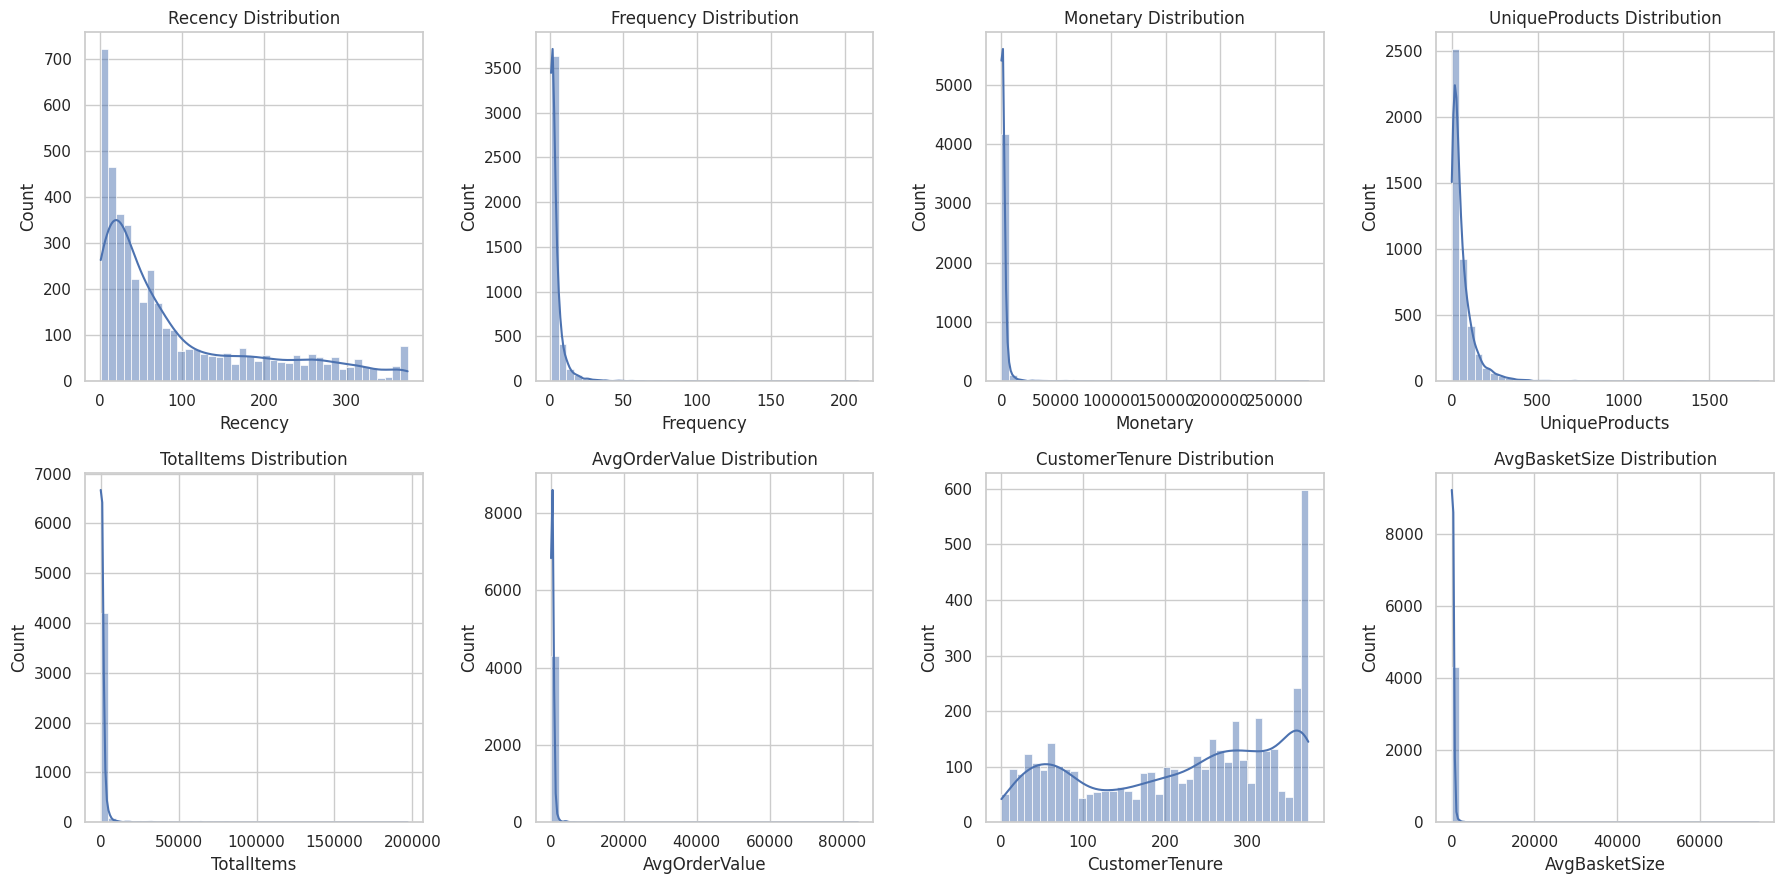

In [166]:

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, col in zip(axes.flatten(), feature_cols):
    sns.histplot(
        data=X,
        x=col,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()


###3 Calculate Skewness

In [167]:

skewness = X.skew().sort_values(ascending=False)

display(
    pd.DataFrame({
        "Feature": skewness.index,
        "Skewness": skewness.values
    })
)


,Feature,Skewness
0,AvgBasketSize,48.008243
1,AvgOrderValue,41.692422
2,TotalItems,20.383991
3,Monetary,19.339368
4,Frequency,12.067031
5,UniqueProducts,6.919445
6,Recency,1.246048
7,CustomerTenure,-0.366508


##Step 14 — Outlier Detection

###14.1 Visualize Outliers with Boxplots

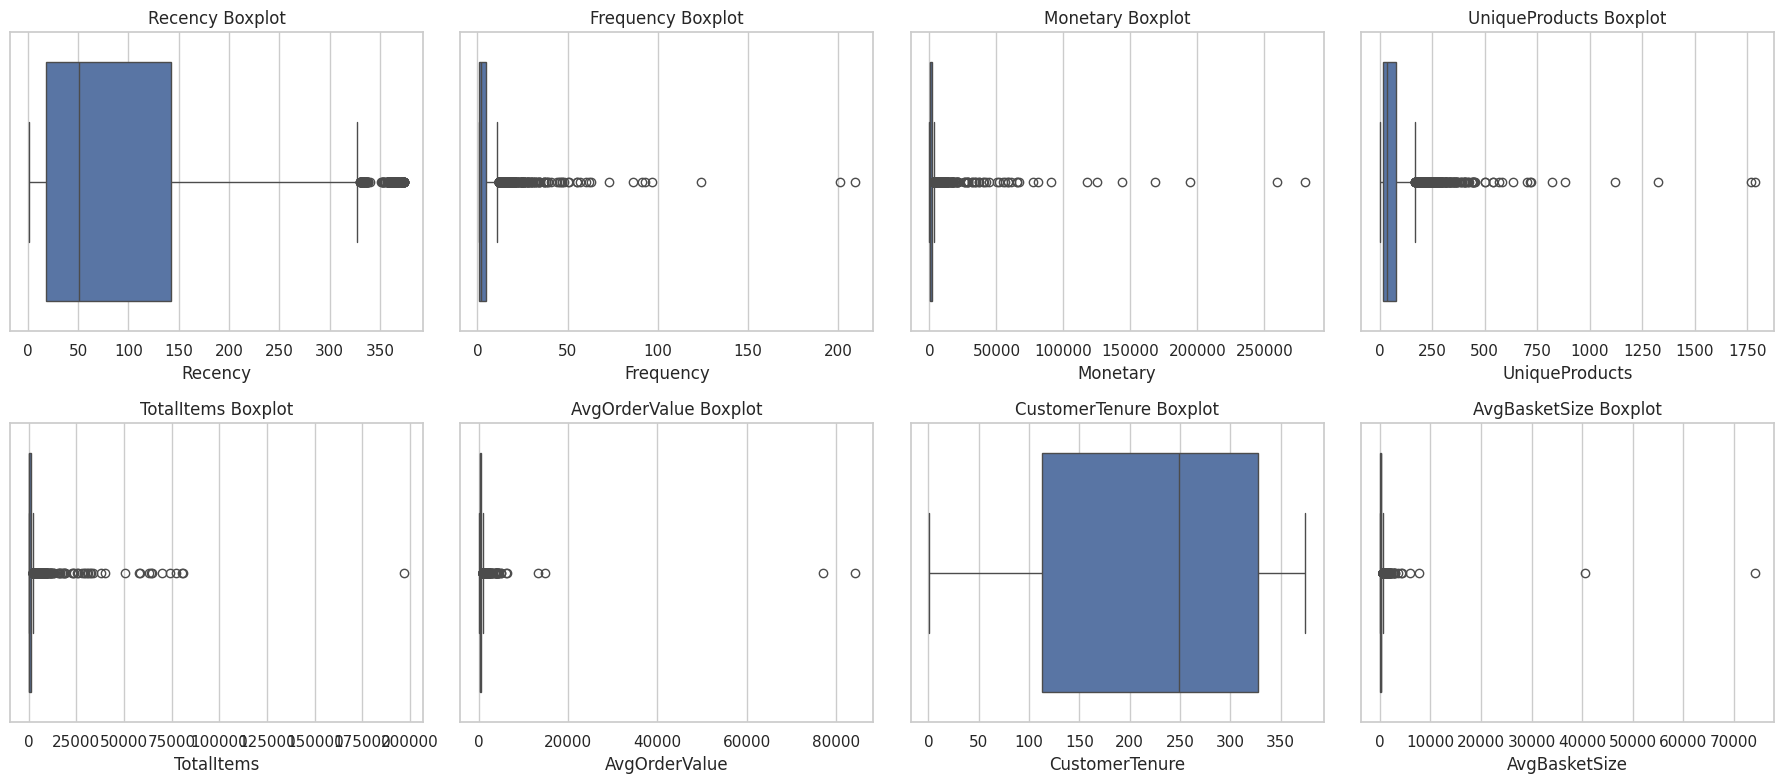

In [168]:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(
        x=X[col],
        ax=ax
    )
    ax.set_title(f"{col} Boxplot")

plt.tight_layout()
plt.show()


In [169]:

outlier_summary = []

for col in feature_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (X[col] < lower) | (X[col] > upper)

    outlier_summary.append({
        "Feature": col,
        "Outlier_Count": outliers.sum(),
        "Outlier_Percentage": round(outliers.mean() * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)


,Feature,Outlier_Count,Outlier_Percentage
0,Recency,155,3.57
1,Frequency,285,6.57
2,Monetary,425,9.80
3,UniqueProducts,309,7.12
4,TotalItems,401,9.24
5,AvgOrderValue,291,6.71
6,CustomerTenure,0,0.00
7,AvgBasketSize,264,6.09


#Feature Transformation & Scaling

##Step 15: Correlation Analysis

###15.1 Correlation Heatmap

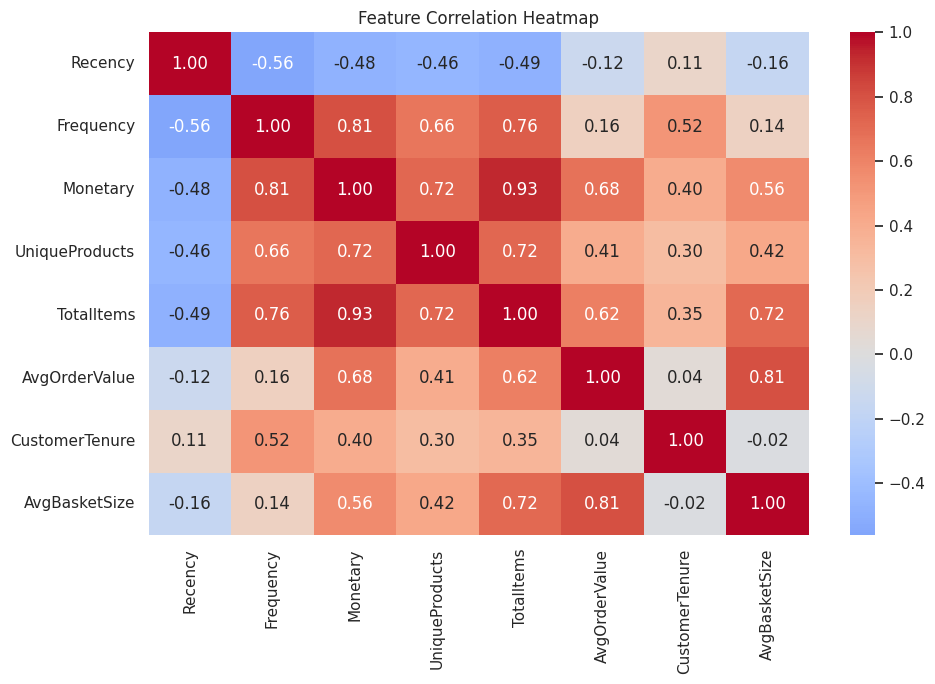

In [170]:

# Spearman correlation handles skewed data
corr_matrix = X.corr(method="spearman")

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


##Step 16: Log Transformation

###16.1 Apply Log Transformation

In [171]:

log_cols = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "TotalItems",
    "AvgOrderValue",
    "AvgBasketSize"
]

X_transformed = X.copy()

X_transformed[log_cols] = np.log1p(
    X_transformed[log_cols]
)

print("Skewness Before:")
display(X.skew().round(2))

print("Skewness After:")
display(X_transformed.skew().round(2))


Skewness Before:


,0
Recency,1.25
Frequency,12.07
Monetary,19.34
UniqueProducts,6.92
TotalItems,20.38
AvgOrderValue,41.69
CustomerTenure,-0.37
AvgBasketSize,48.01


Skewness After:


,0
Recency,-0.38
Frequency,1.21
Monetary,0.40
UniqueProducts,-0.24
TotalItems,0.04
AvgOrderValue,0.24
CustomerTenure,-0.37
AvgBasketSize,-0.36


###16.2 Visualize Before vs After

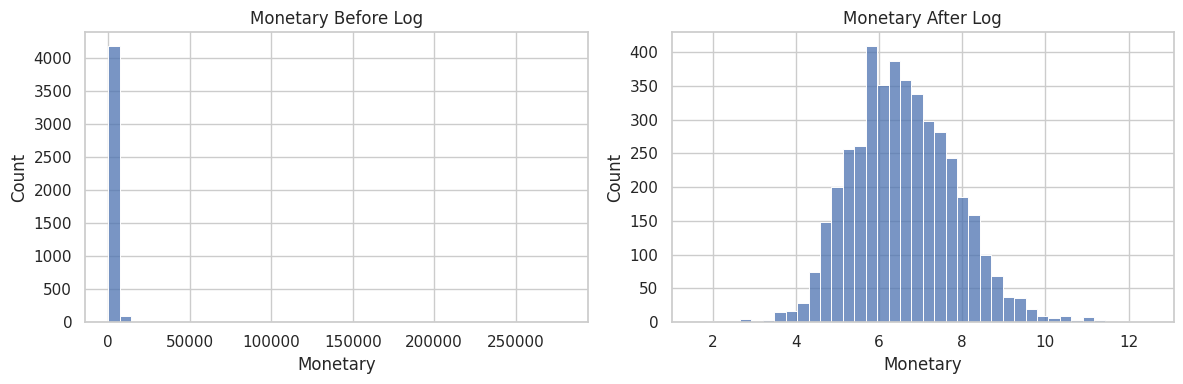

In [172]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    X["Monetary"],
    bins=40,
    ax=axes[0]
)
axes[0].set_title("Monetary Before Log")

sns.histplot(
    X_transformed["Monetary"],
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Monetary After Log")

plt.tight_layout()
plt.show()


##Step 17: Feature Scaling

###17.1 Compare Scalers

In [173]:
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler
)

In [174]:
standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

In [175]:
X_standard = standard_scaler.fit_transform(
    X_transformed
)

In [176]:
X_robust = robust_scaler.fit_transform(
    X_transformed
)

In [177]:
print("StandardScaler Shape:", X_standard.shape)
print("RobustScaler Shape:", X_robust.shape)

print("StandardScaler Mean:",
      X_standard.mean(axis=0).round(3))

print("RobustScaler Median:",
      np.median(X_robust, axis=0).round(3))

StandardScaler Shape: (4338, 8)
RobustScaler Shape: (4338, 8)
StandardScaler Mean: [-0. -0. -0.  0. -0.  0. -0.  0.]
RobustScaler Median: [ 0.  0. -0.  0.  0.  0.  0.  0.]


#Feature Selection & Clustering Experiments

##Step 18 — Feature Selection

### Experiment A: Traditional RFM

In [178]:
rfm_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

#### Experiment B: Extended customer behavior

In [179]:
extended_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "CustomerTenure"
]


In [180]:
print("RFM Features:", rfm_features)
print("Extended Features:", extended_features)

RFM Features: ['Recency', 'Frequency', 'Monetary']
Extended Features: ['Recency', 'Frequency', 'Monetary', 'UniqueProducts', 'CustomerTenure']


##Step 19 — Prepare Clustering Experiments

In [181]:
experiments = {
    "RFM_Standard": StandardScaler().fit_transform(
        X_transformed[rfm_features]
    ),

    "RFM_Robust": RobustScaler().fit_transform(
        X_transformed[rfm_features]
    ),

    "Extended_Standard": StandardScaler().fit_transform(
        X_transformed[extended_features]
    ),

    "Extended_Robust": RobustScaler().fit_transform(
        X_transformed[extended_features]
    )
}

for name, data in experiments.items():
    print(name, data.shape)


RFM_Standard (4338, 3)
RFM_Robust (4338, 3)
Extended_Standard (4338, 5)
Extended_Robust (4338, 5)


##Step 20 — Elbow Method & Silhouette Score

###20.1 Train K-Means for Different K Values

In [182]:
results = []

for experiment_name, data in experiments.items():

    for k in range(2, 11):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(data)

        silhouette = silhouette_score(
            data,
            labels,
            sample_size=2000,
            random_state=42
        )

        results.append({
            "Experiment": experiment_name,
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette
        })




In [183]:
results_df = pd.DataFrame(results)

display(results_df)

,Experiment,K,Inertia,Silhouette
0,RFM_Standard,2,6483.589425,0.425610
1,RFM_Standard,3,4869.488629,0.328408
2,RFM_Standard,4,3939.049382,0.332984
3,RFM_Standard,5,3296.708708,0.317956
4,RFM_Standard,6,2855.764068,0.316730
5,RFM_Standard,7,2548.820245,0.309859
6,RFM_Standard,8,2336.341054,0.301870
7,RFM_Standard,9,2156.005673,0.277872
8,RFM_Standard,10,2005.746236,0.276632
9,RFM_Robust,2,2996.452615,0.423066


###20.2 Visualize Elbow Curves

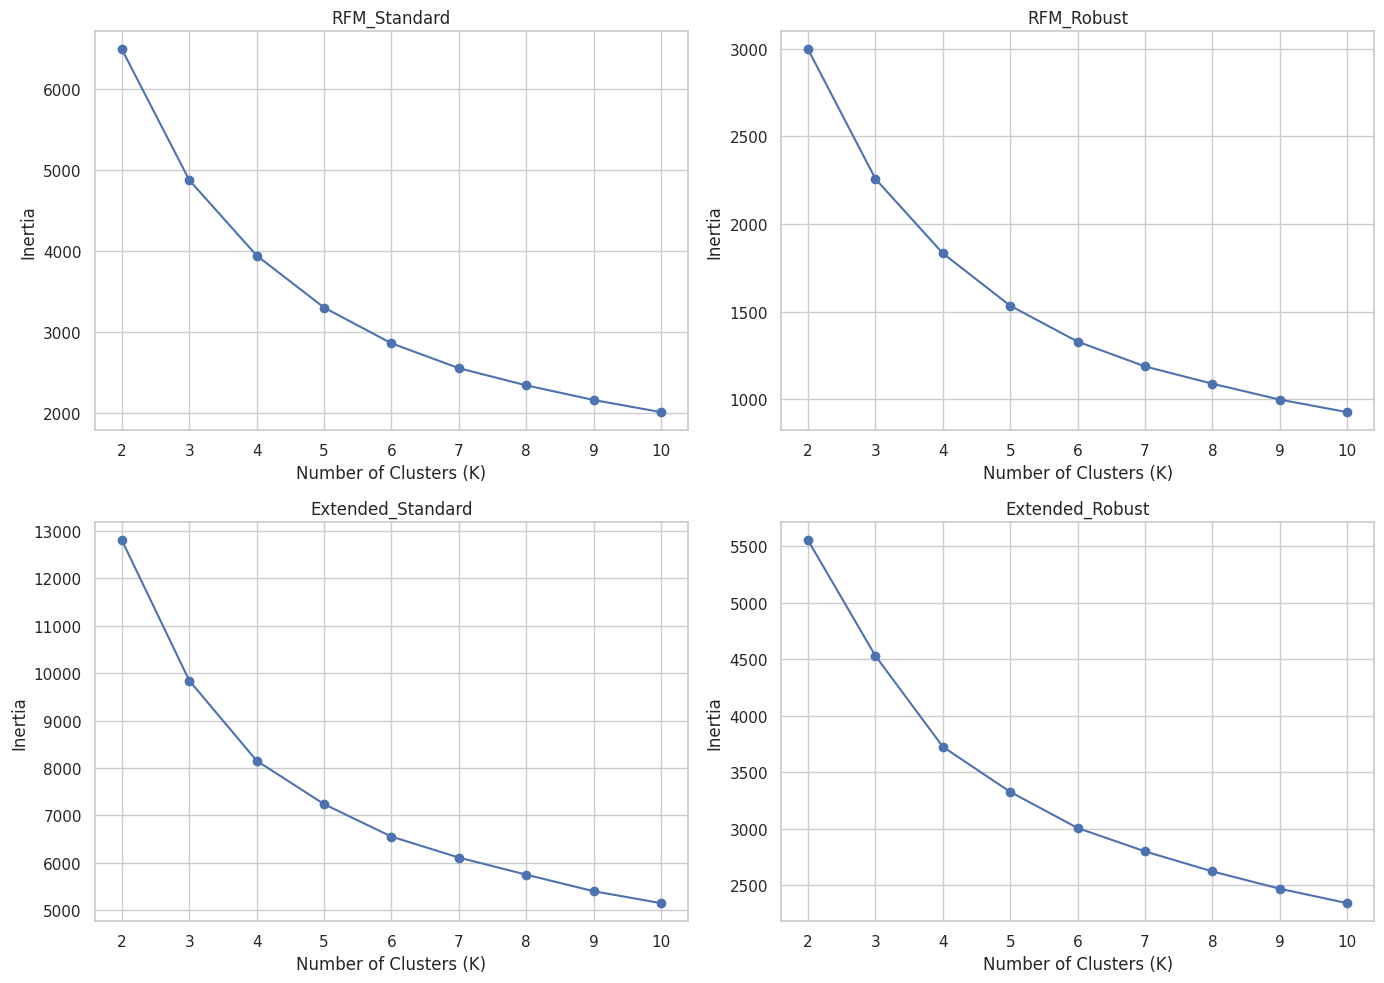

In [184]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, group) in zip(
    axes.flatten(),
    results_df.groupby("Experiment", sort=False)
):
    ax.plot(
        group["K"],
        group["Inertia"],
        marker="o"
    )

    ax.set_title(name)
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_ylabel("Inertia")
    ax.grid(True)

plt.tight_layout()
plt.show()


###20.3 Compare Silhouette Scores

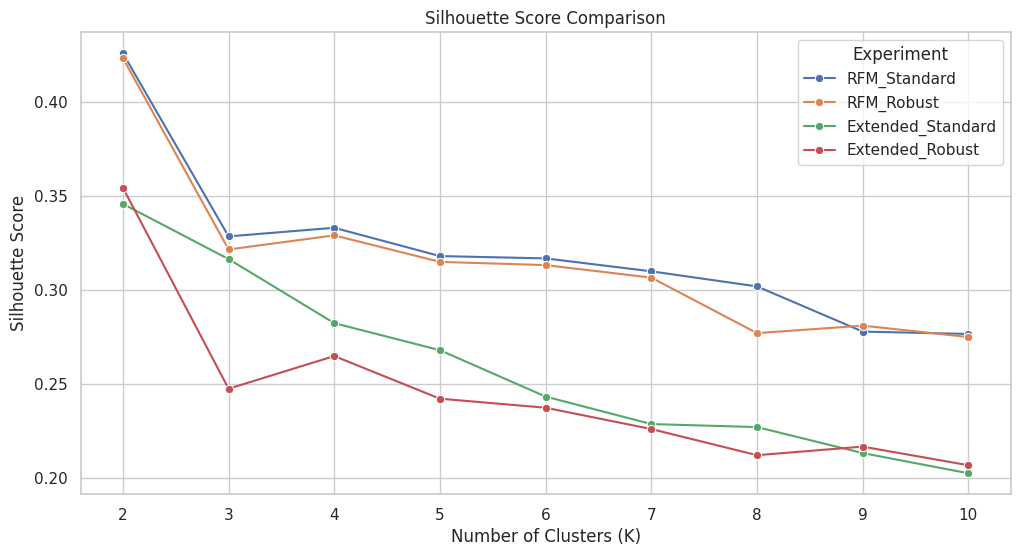

In [185]:

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=results_df,
    x="K",
    y="Silhouette",
    hue="Experiment",
    marker="o"
)

plt.title("Silhouette Score Comparison")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


In [186]:

best_results = (
    results_df
    .sort_values("Silhouette", ascending=False)
    .drop_duplicates(subset="Experiment")
)

display(best_results)


,Experiment,K,Inertia,Silhouette
0,RFM_Standard,2,6483.589425,0.425610
9,RFM_Robust,2,2996.452615,0.423066
27,Extended_Robust,2,5552.555610,0.354245
18,Extended_Standard,2,12802.132841,0.345652


###20.4 — Alternative Clustering Algorithms Comparison

In [187]:

# Same dataset for fair comparison
X_compare = experiments["RFM_Standard"]

comparison_results = []

for k in [2, 3, 4, 5]:

    models = {
        "K-Means": KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        ),

        "Agglomerative": AgglomerativeClustering(
            n_clusters=k
        ),

        "GMM": GaussianMixture(
            n_components=k,
            random_state=42,
            n_init=5
        )
    }

    for name, model in models.items():

        labels = model.fit_predict(X_compare)

        comparison_results.append({
            "Algorithm": name,
            "K": k,
            "Silhouette": silhouette_score(
                X_compare, labels
            ),
            "Davies-Bouldin": davies_bouldin_score(
                X_compare, labels
            )
        })




In [188]:
comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "Silhouette",
        ascending=False
    ).round(3)
)

,Algorithm,K,Silhouette,Davies-Bouldin
0,K-Means,2,0.433,0.892
1,Agglomerative,2,0.404,0.940
6,K-Means,4,0.337,1.011
3,K-Means,3,0.337,1.048
9,K-Means,5,0.316,0.988
2,GMM,2,0.285,1.067
4,Agglomerative,3,0.284,1.133
10,Agglomerative,5,0.281,1.031
7,Agglomerative,4,0.280,1.099
5,GMM,3,0.258,1.217


#Cluster Validation

##Step 21 — Compare Candidate K Values

In [189]:

from sklearn.metrics import (
    davies_bouldin_score,
    calinski_harabasz_score
)

X_model = experiments["RFM_Standard"]

candidate_results = []
candidate_models = {}

for k in [2, 3, 4, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_model)
    candidate_models[k] = model

    cluster_sizes = pd.Series(labels).value_counts()

    candidate_results.append({
        "K": k,
        "Silhouette": silhouette_score(
            X_model, labels
        ),
        "Davies_Bouldin": davies_bouldin_score(
            X_model, labels
        ),
        "Calinski_Harabasz": calinski_harabasz_score(
            X_model, labels
        ),
        "Smallest_Cluster": cluster_sizes.min(),
        "Smallest_Cluster_Pct": (
            cluster_sizes.min() / len(labels) * 100
        )
    })




In [190]:
candidate_df = pd.DataFrame(candidate_results)

display(candidate_df.round(3))

,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster,Smallest_Cluster_Pct
0,2,0.433,0.892,4367.323,1666,38.405
1,3,0.337,1.048,3625.303,769,17.727
2,4,0.337,1.011,3328.919,709,16.344
3,5,0.316,0.988,3192.977,339,7.815


##Step 22 — Analyze Cluster Sizes

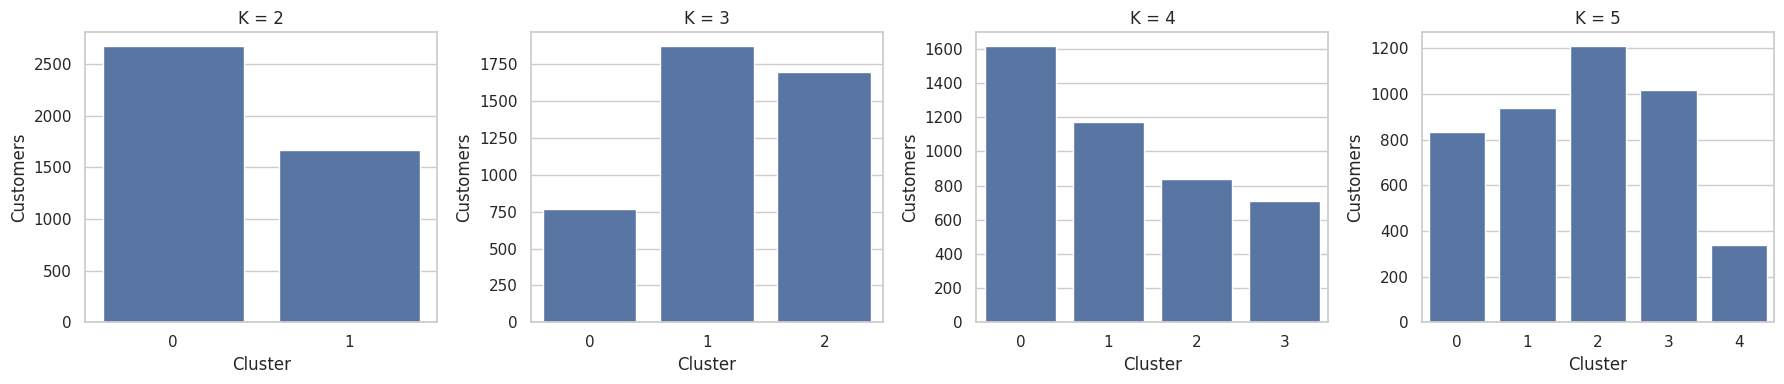

In [191]:

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, k in zip(axes, [2, 3, 4, 5]):

    labels = candidate_models[k].labels_

    sizes = pd.Series(labels).value_counts().sort_index()

    sns.barplot(
        x=sizes.index.astype(str),
        y=sizes.values,
        ax=ax
    )

    ax.set_title(f"K = {k}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Customers")

plt.tight_layout()
plt.show()


##Step 23 — Compare Customer Profiles

In [192]:
profile_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "UniqueProducts",
    "AvgOrderValue",
    "CustomerTenure"
]

In [193]:
for k in [2, 3, 4, 5]:

    temp = customer_features.copy()

    temp["Cluster"] = candidate_models[k].labels_

    print(f"\n===== K = {k} =====")

    profile = temp.groupby("Cluster").agg(
        Customers=("CustomerID", "count"),
        **{
            col: (col, "median")
            for col in profile_features
        }
    )

    display(profile.round(2))



===== K = 2 =====


,Customers,Recency,Frequency,Monetary,UniqueProducts,AvgOrderValue,CustomerTenure
Cluster,,,,,,,
0,2672,96.0,1.0,363.08,22.0,239.40,204.0
1,1666,16.0,6.0,2061.08,86.0,346.26,305.0



===== K = 3 =====


,Customers,Recency,Frequency,Monetary,UniqueProducts,AvgOrderValue,CustomerTenure
Cluster,,,,,,,
0,769,9.0,10.0,3701.44,115.0,372.06,355.0
1,1872,158.0,1.0,296.09,17.0,222.68,206.5
2,1697,30.0,3.0,974.42,50.0,311.64,240.0



===== K = 4 =====


,Customers,Recency,Frequency,Monetary,UniqueProducts,AvgOrderValue,CustomerTenure
Cluster,,,,,,,
0,1617,177.0,1.0,298.40,17.0,225.12,219.0
1,1173,55.0,4.0,1341.65,59.0,360.01,279.0
2,839,17.0,2.0,466.70,31.0,226.70,65.0
3,709,8.0,10.0,3722.82,117.0,369.06,358.0



===== K = 5 =====


,Customers,Recency,Frequency,Monetary,UniqueProducts,AvgOrderValue,CustomerTenure
Cluster,,,,,,,
0,834,24.0,2.0,352.70,25.0,216.23,47.0
1,938,16.0,5.0,1831.95,82.0,323.28,285.0
2,1209,212.0,1.0,247.39,15.0,202.65,236.0
3,1018,80.0,3.0,1011.95,46.0,358.09,269.0
4,339,7.0,15.0,6211.66,150.0,405.46,365.0


##Step 24 — Visualize Cluster Profiles

In [194]:
k = 2

temp = customer_features.copy()
temp["Cluster"] = candidate_models[k].labels_


In [195]:
profile = temp.groupby("Cluster")[
    profile_features
].median()

In [196]:
# Compare relative feature levels
overall_median = customer_features[
    profile_features
].median()

In [197]:

relative_profile = (
    profile / overall_median.replace(0, np.nan)
)

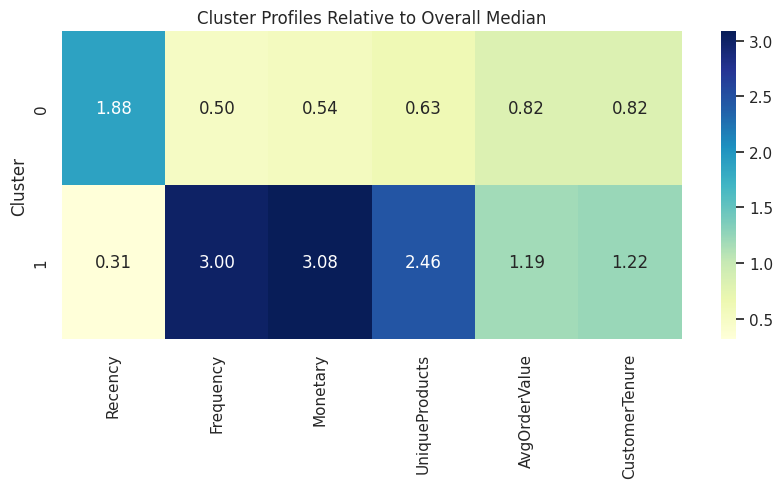

In [198]:

plt.figure(figsize=(10, 4))

sns.heatmap(
    relative_profile,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Cluster Profiles Relative to Overall Median")
plt.ylabel("Cluster")
plt.show()


#Cluster Stability & PCA Visualization

##Step 25 — Cluster Stability Testing

In [199]:
stability_results = []

for k in [2, 4]:

    reference_labels = candidate_models[k].labels_

    for seed in range(5):

        X_train, _ = train_test_split(
            X_model,
            train_size=0.8,
            random_state=seed
        )

        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=20
        )

        model.fit(X_train)

        # Predict all customers for fair comparison
        new_labels = model.predict(X_model)

        ari = adjusted_rand_score(
            reference_labels,
            new_labels
        )

        stability_results.append({
            "K": k,
            "Seed": seed,
            "ARI": ari
        })


In [200]:
stability_df = pd.DataFrame(stability_results)

display(
    stability_df.groupby("K")["ARI"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)


,mean,std,min,max
K,,,,
2,0.992,0.004,0.988,0.997
4,0.956,0.021,0.931,0.979


##Step 26 — PCA Visualization

###26.1 Apply PCA

In [201]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_model)

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_.round(3)
)

print(
    "Total Explained Variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Explained Variance Ratio: [0.751 0.188]
Total Explained Variance: 93.87 %


###26.2 Visualize K=2 vs K=4

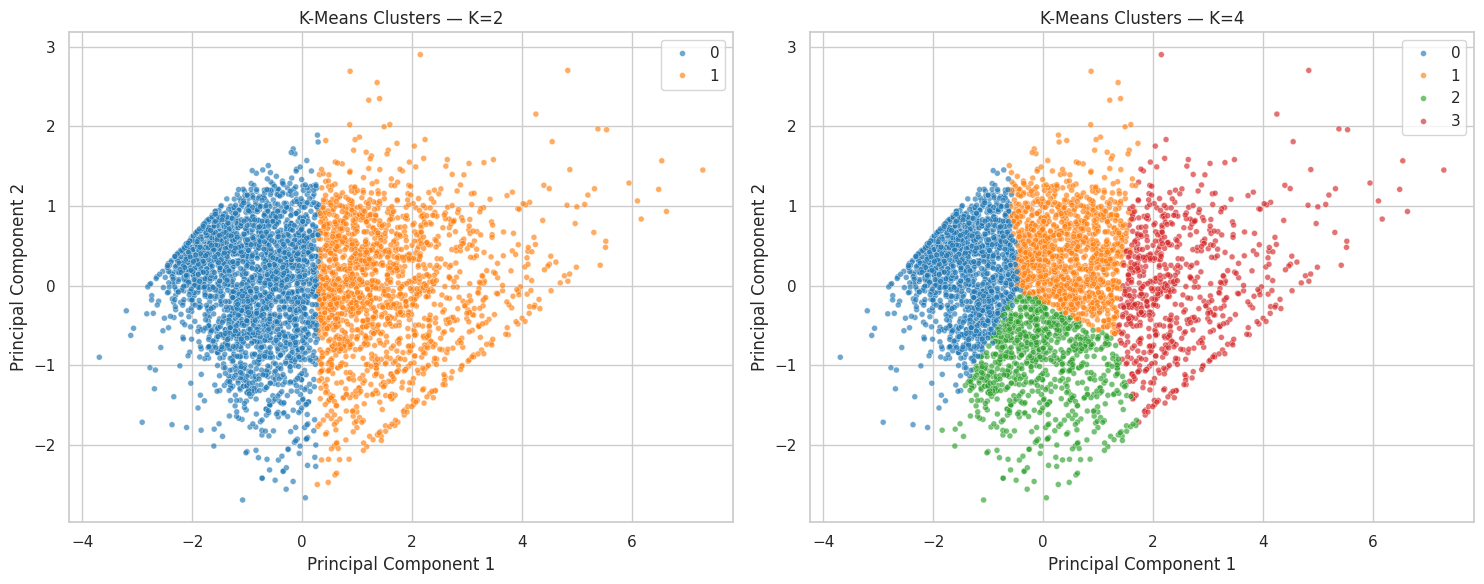

In [202]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, k in zip(axes, [2, 4]):

    labels = candidate_models[k].labels_

    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=labels,
        palette="tab10",
        s=18,
        alpha=0.65,
        ax=ax
    )

    ax.set_title(f"K-Means Clusters — K={k}")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()


##Step 27 — Compare Stability Visually

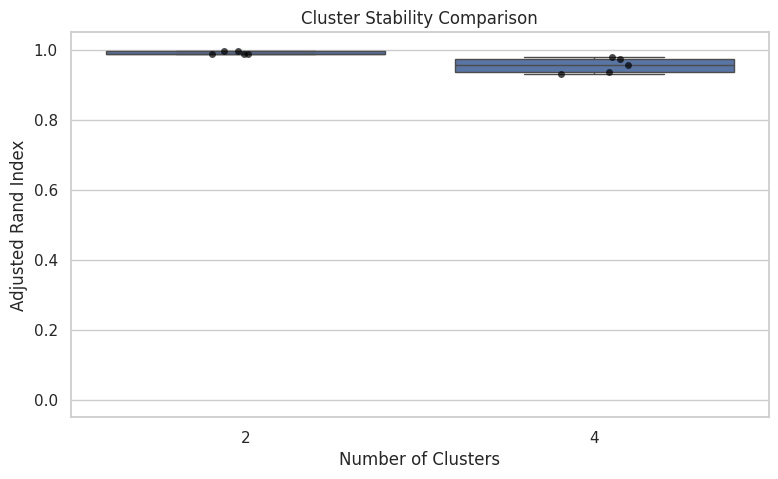

In [203]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=stability_df,
    x="K",
    y="ARI"
)

sns.stripplot(
    data=stability_df,
    x="K",
    y="ARI",
    color="black",
    alpha=0.7
)

plt.title("Cluster Stability Comparison")
plt.ylabel("Adjusted Rand Index")
plt.xlabel("Number of Clusters")
plt.ylim(-0.05, 1.05)
plt.show()


# Final Model & Customer Segmentation Report

##Step 28 — Final K-Means Model

In [204]:
final_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

# Use the existing log-transformed features
X_final = X_transformed[final_features].copy()

# Fit and save scaler
final_scaler = StandardScaler()
X_final_scaled = final_scaler.fit_transform(X_final)

# Train final model
final_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

final_labels = final_model.fit_predict(
    X_final_scaled
)

# Add labels to customer table
customer_segments = customer_features.copy()
customer_segments["Cluster"] = final_labels

print("Final model:", final_model)
print("Total customers:", len(customer_segments))

display(
    customer_segments["Cluster"]
    .value_counts()
    .sort_index()
)


Final model: KMeans(n_clusters=4, n_init=20, random_state=42)
Total customers: 4338


,count
Cluster,
0,1617
1,1173
2,839
3,709


In [205]:
print(
    "Agreement with previous K=4 model:",
    adjusted_rand_score(
        candidate_models[4].labels_,
        final_labels
    )
)


Agreement with previous K=4 model: 1.0


##Step 29 — Business Segment Analysis

In [206]:

segment_report = customer_segments.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    MedianRecency=("Recency", "median"),
    AvgFrequency=("Frequency", "mean"),
    MedianFrequency=("Frequency", "median"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median"),
    TotalRevenue=("Monetary", "sum"),
    AvgOrderValue=("AvgOrderValue", "mean")
)



In [207]:
segment_report["CustomerShare_%"] = (
    segment_report["Customers"]
    / segment_report["Customers"].sum() * 100
)

segment_report["RevenueShare_%"] = (
    segment_report["TotalRevenue"]
    / segment_report["TotalRevenue"].sum() * 100
)

display(segment_report.round(2))

,Customers,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,TotalRevenue,AvgOrderValue,CustomerShare_%,RevenueShare_%
Cluster,,,,,,,,,,,
0,1617,182.63,177.0,1.32,1.0,347.85,298.40,562469.24,288.08,37.28,6.33
1,1173,70.13,55.0,4.11,4.0,1804.82,1341.65,2117050.02,571.27,27.04,23.82
2,839,18.21,17.0,2.14,2.0,543.06,466.70,455624.56,278.34,19.34,5.13
3,709,12.08,8.0,13.79,10.0,8112.93,3722.82,5752065.07,623.83,16.34,64.72


###Step 29.1 — Customer Share vs Revenue Share

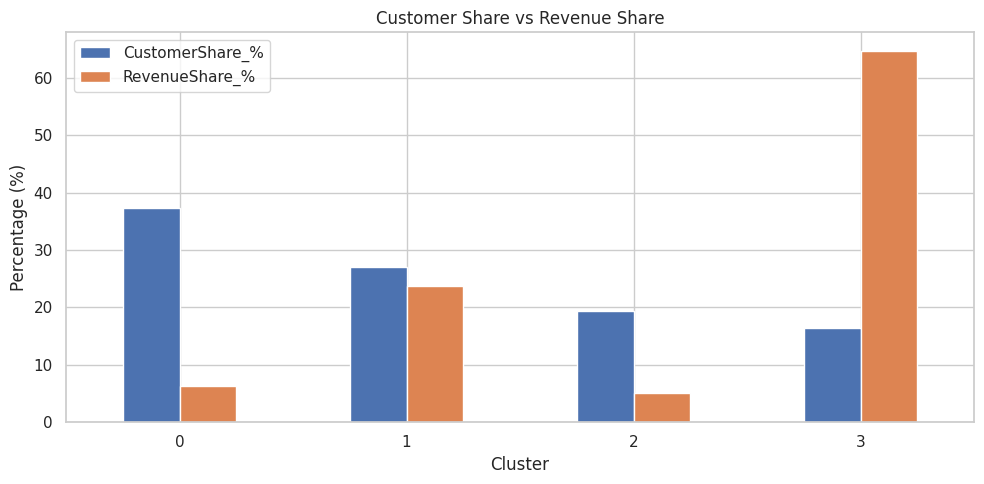

In [208]:

comparison = segment_report[
    ["CustomerShare_%", "RevenueShare_%"]
]

comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer Share vs Revenue Share")
plt.xlabel("Cluster")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


##Step 30 — Marketing Recommendations

In [209]:

segment_names = {
    0: "At-Risk",
    1: "Regular",
    2: "Recent / Developing",
    3: "High-Value Loyal"
}



In [210]:
marketing_actions = {
    0: "Win-back campaigns and personalized offers",
    1: "Loyalty rewards and cross-selling",
    2: "Second-purchase incentives",
    3: "VIP benefits and priority retention"
}


In [211]:
customer_segments["Segment"] = (
    customer_segments["Cluster"].map(segment_names)
)

segment_report["Segment"] = (
    segment_report.index.map(segment_names)
)

segment_report["MarketingAction"] = (
    segment_report.index.map(marketing_actions)
)

display(segment_report.round(2))

,Customers,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,TotalRevenue,AvgOrderValue,CustomerShare_%,RevenueShare_%,Segment,MarketingAction
Cluster,,,,,,,,,,,,,
0,1617,182.63,177.0,1.32,1.0,347.85,298.40,562469.24,288.08,37.28,6.33,At-Risk,Win-back campaigns and personalized offers
1,1173,70.13,55.0,4.11,4.0,1804.82,1341.65,2117050.02,571.27,27.04,23.82,Regular,Loyalty rewards and cross-selling
2,839,18.21,17.0,2.14,2.0,543.06,466.70,455624.56,278.34,19.34,5.13,Recent / Developing,Second-purchase incentives
3,709,12.08,8.0,13.79,10.0,8112.93,3722.82,5752065.07,623.83,16.34,64.72,High-Value Loyal,VIP benefits and priority retention


##Save Results & Model

In [212]:

import joblib

# Save customer labels
customer_segments.to_csv(
    "customer_segments.csv",
    index=False
)

# Save segment report
segment_report.to_csv(
    "segment_report.csv"
)

# Save trained model and scaler
joblib.dump(
    final_model,
    "kmeans_customer_model.pkl"
)

joblib.dump(
    final_scaler,
    "customer_scaler.pkl"
)

print("All files saved successfully.")


All files saved successfully.
